# Terrain

In mountains, the shape of the ground controls almost everything a satellite sees: how much sunlight a slope gets,
how cold it is, where snow lasts, where water flows. A **digital elevation model** (DEM) describes that shape, and
from it come slope, aspect, shading and corrections. This notebook works with the Copernicus 30 m DEM over the Hunza
valley, where the ground rises from about 2,000 m at the river to over 7,000 m on Rakaposhi and Ultar within 15 km.

What you will learn: how DEMs are made and what their heights mean; slope and aspect from finite differences;
hillshade; how the angle between sun and slope sets illumination; topographic correction of an image; elevation bands
and hypsometry; valley profiles and the geology behind them; and lapse rates.

In [1]:
import importlib.util, subprocess, sys
need = {"pystac_client": "pystac-client", "planetary_computer": "planetary-computer", "rasterio": "rasterio"}
missing = [p for m, p in need.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.merge import merge
import pystac_client, planetary_computer
plt.rcParams.update({"figure.dpi": 110})
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
BBOX = [74.55, 36.25, 74.75, 36.40]

# What a DEM is

A DEM is a raster whose values are heights. Two kinds matter:

* a **digital surface model** (DSM) gives the height of whatever the sensor first hits: tree tops, roofs, ice;
* a **digital terrain model** (DTM) gives the bare ground, with vegetation and buildings removed.

Global DEMs are made by measuring the same ground from two viewpoints. **SRTM** (2000) and **Copernicus DEM** (from the
TanDEM-X mission, 2011-2015) use **radar interferometry**: two radar antennas a known distance apart receive the echo
from each point, and the tiny difference in the travel time (seen as a phase difference of the radar wave) gives the
height by trigonometry. **ASTER** and **ALOS** DEMs use optical **stereo**: two images from different angles, as our
two eyes judge depth. Copernicus GLO-30 is a DSM at 30 m with a typical vertical error of a few metres, larger on steep
slopes and in radar shadow.

**What "height" means.** Heights need a zero. GPS measures height above the **ellipsoid**; maps use height above the
**geoid**, the surface the sea would take if it extended under the land, which follows the pull of gravity and differs
from the ellipsoid by up to 100 m (in this region the geoid is about 30 m below it). Copernicus DEM heights are above
the EGM2008 geoid, so they match "metres above sea level" on maps.

In [2]:
dems = list(catalog.search(collections=["cop-dem-glo-30"], bbox=BBOX).items())
print("DEM tiles covering the area:", [d.id for d in dems])
srcs = [rasterio.open(d.assets["data"].href) for d in dems]
dem, dtf = merge(srcs, bounds=BBOX)
crs = srcs[0].crs
for s in srcs:
    s.close()
dem = dem[0].astype("float64")
print("CRS:", crs, "| pixel:", round(dtf.a * 3600, 2), "x", round(-dtf.e * 3600, 2), "arc-seconds | grid:", dem.shape)
print(f"height range {dem.min():,.0f} to {dem.max():,.0f} m; relief {dem.max() - dem.min():,.0f} m in a {abs(BBOX[2]-BBOX[0])*111*np.cos(np.radians(36.3)):.0f} km wide box")

DEM tiles covering the area: ['Copernicus_DSM_COG_10_N36_00_E074_00_DEM']


CRS: EPSG:4326 | pixel: 1.0 x 1.0 arc-seconds | grid: (540, 720)
height range 1,930 to 7,302 m; relief 5,371 m in a 18 km wide box


# Slope and aspect

**Slope** is how steep the ground is; **aspect** is the compass direction it faces. Both come from the rate of change
of height in the east-west and north-south directions, $\partial z/\partial x$ and $\partial z/\partial y$. On a grid
these derivatives are estimated by **finite differences**: the difference between neighbours divided by their
distance. Horn's method (1981), used by most GIS software, weights the eight neighbours of each cell:

$$\frac{\partial z}{\partial x} \approx \frac{(z_3 + 2z_6 + z_9) - (z_1 + 2z_4 + z_7)}{8\,\Delta x}, \qquad
\frac{\partial z}{\partial y} \approx \frac{(z_7 + 2z_8 + z_9) - (z_1 + 2z_2 + z_3)}{8\,\Delta y}$$

with cells numbered 1-9 from top left. Then

$$\text{slope} = \arctan\sqrt{\left(\frac{\partial z}{\partial x}\right)^2 + \left(\frac{\partial z}{\partial y}\right)^2}, \qquad
\text{aspect} = \operatorname{atan2}\!\left(-\frac{\partial z}{\partial x}, \frac{\partial z}{\partial y}\right),$$

measured clockwise from north. One trap: this DEM's pixels are in **degrees**, so $\Delta x$ and $\Delta y$ must be
converted to metres first. A degree of latitude is about 111.3 km everywhere, but a degree of longitude shrinks with
$\cos(\text{latitude})$: at 36.3 N it is only about 89.7 km.

In [3]:
lat0 = np.radians((BBOX[1] + BBOX[3]) / 2)
dx = dtf.a * 111320 * np.cos(lat0)                 # metres per pixel east-west
dy = -dtf.e * 110950                               # metres per pixel north-south (a degree of latitude near 36 N)
def horn(dem, dx, dy):
    """Slope and aspect (degrees) by Horn's method; dx, dy are pixel sizes in metres; rows run north to south."""
    z = np.pad(dem, 1, mode="edge")
    z1, z2, z3 = z[:-2, :-2], z[:-2, 1:-1], z[:-2, 2:]
    z4, z6 = z[1:-1, :-2], z[1:-1, 2:]
    z7, z8, z9 = z[2:, :-2], z[2:, 1:-1], z[2:, 2:]
    dzdx = ((z3 + 2 * z6 + z9) - (z1 + 2 * z4 + z7)) / (8 * dx)
    dzdy = ((z7 + 2 * z8 + z9) - (z1 + 2 * z2 + z3)) / (8 * dy)  # positive when height increases southwards
    slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    aspect = (np.degrees(np.arctan2(-dzdx, dzdy)) + 360) % 360  # direction the slope faces, 0 = north, 90 = east
    return slope, aspect

slope, aspect = horn(dem, dx, dy)
print(f"pixel size: {dx:.1f} m east-west, {dy:.1f} m north-south")
print(f"slope: median {np.median(slope):.0f} deg, 90th percentile {np.percentile(slope, 90):.0f} deg, steepest {slope.max():.0f} deg")
# a check on surfaces whose answer we know: a plane rising 1 m per metre eastwards has slope 45 deg and faces west (270);
# one rising southwards faces north (0)
xx = np.arange(7)[None, :].repeat(7, 0) * 30.0
for name, surf in [("rising east", xx), ("rising south", xx.T)]:
    s_, a_ = horn(surf, 30.0, 30.0)
    print(f"known-answer test, plane {name}: slope {s_[3, 3]:.1f} deg, aspect {a_[3, 3]:.0f} deg")

pixel size: 24.9 m east-west, 30.8 m north-south
slope: median 38 deg, 90th percentile 55 deg, steepest 81 deg
known-answer test, plane rising east: slope 45.0 deg, aspect 270 deg
known-answer test, plane rising south: slope 45.0 deg, aspect 0 deg


# Hillshade: how the Sun lights the slopes

The brightness of a slope in sunlight depends on the angle $i$ between the Sun's rays and the perpendicular to the
slope (the **incidence angle**). For a sun at zenith angle $\theta_z$ (angle from straight up) and azimuth $\phi_s$, and
a slope $s$ facing $a$, spherical trigonometry gives

$$\cos i = \cos\theta_z \cos s + \sin\theta_z \sin s \cos(\phi_s - a).$$

A slope facing the sun has $\cos i$ near 1, a slope facing away near 0 or negative (in shadow). A **hillshade** is just
$\cos i$ drawn in grey, with an imagined sun usually from the north-west at 45 degrees, because our eyes read relief
best when light comes from the top of the picture.

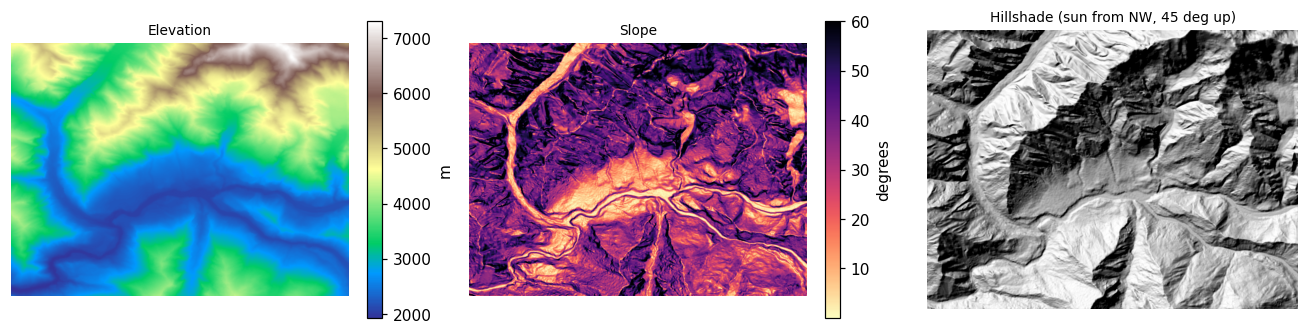

In [4]:
def cos_incidence(slope_deg, aspect_deg, sun_zenith, sun_azimuth):
    s, a = np.radians(slope_deg), np.radians(aspect_deg)
    tz, ps = np.radians(sun_zenith), np.radians(sun_azimuth)
    return np.cos(tz) * np.cos(s) + np.sin(tz) * np.sin(s) * np.cos(ps - a)

hill = cos_incidence(slope, aspect, 45, 315)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
im0 = ax[0].imshow(dem, cmap="terrain")
plt.colorbar(im0, ax=ax[0], fraction=0.04, label="m")
ax[0].set_title("Elevation", fontsize=9)
im1 = ax[1].imshow(slope, cmap="magma_r", vmax=60)
plt.colorbar(im1, ax=ax[1], fraction=0.04, label="degrees")
ax[1].set_title("Slope", fontsize=9)
ax[2].imshow(hill, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Hillshade (sun from NW, 45 deg up)", fontsize=9)
for a in ax:
    a.set_axis_off()
plt.tight_layout()
plt.show()

# Topographic correction

With the real sun position at the moment an image was taken, $\cos i$ says how much more or less light each slope
received than flat ground. The simplest **cosine correction** divides that out: $\rho_{flat} = \rho \cdot \cos\theta_z / \cos i$.
It over-corrects slopes facing away from the sun, because those still receive light scattered from the sky and from
neighbouring slopes. The **C-correction** (Teillet et al. 1982) fixes that with a constant $c$ estimated from the image
itself: regress reflectance on $\cos i$ ($\rho = m \cos i + b$), set $c = b/m$, and use

$$\rho_{flat} = \rho \cdot \frac{\cos\theta_z + c}{\cos i + c}.$$

A good correction removes the relationship between brightness and illumination: afterwards, sunlit and shaded slopes
of the same surface look alike. So the first question to ask of any image is whether that relationship is there at
all. We check the Sentinel-2 Level-2A image from the physics notebook, on its own UTM grid with the DEM reprojected
onto it.

In [5]:
item = sorted(catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime="2025-03-01/2025-04-30",
                             query={"eo:cloud_cover": {"lt": 15}}).items(), key=lambda i: i.properties["eo:cloud_cover"])[0]
sz, sa = item.properties["s2:mean_solar_zenith"], item.properties["s2:mean_solar_azimuth"]
print(item.id[:38], "| sun zenith", round(sz, 1), "| sun azimuth", round(sa, 1))
# Everything goes on the image's own grid (UTM, 30 m, averaging the 10 m pixels); the DEM is reprojected onto it with
# bilinear resampling, since heights are continuous, and slope is then computed in metres directly.
with rasterio.open(item.assets["B04"].href) as src:
    win = from_bounds(*transform_bounds("EPSG:4326", src.crs, *BBOX), src.transform)
    shape30 = (int(win.height // 3), int(win.width // 3))
    red = src.read(1, window=win, out_shape=shape30, resampling=Resampling.average).astype("float64")
    utm, tf30 = src.crs, src.window_transform(win) * rasterio.Affine.scale(win.width / shape30[1], win.height / shape30[0])
with rasterio.open(item.assets["SCL"].href) as s:
    scl = s.read(1, window=from_bounds(*transform_bounds("EPSG:4326", s.crs, *BBOX), s.transform), out_shape=shape30,
                 resampling=Resampling.nearest)
dem_utm = np.zeros(shape30)
reproject(dem, dem_utm, src_transform=dtf, src_crs=crs, dst_transform=tf30, dst_crs=utm, resampling=Resampling.bilinear)
slope_u, aspect_u = horn(dem_utm, tf30.a, -tf30.e)
red = np.where(red == 0, np.nan, (red - 1000) / 10000)
cosi = cos_incidence(slope_u, aspect_u, sz, sa)
snow = (scl == 11) & np.isfinite(red) & (cosi > 0.05)
print(f"snow pixels: {snow.sum():,}; correlation of red reflectance with cos i: {np.corrcoef(cosi[snow], red[snow])[0, 1]:.3f}")
hi = snow & (red > 1)
print(f"pixels above 1: {hi.sum():,}; their median cos i {np.median(cosi[hi]):.2f} (all snow {np.median(cosi[snow]):.2f}),",
      f"median slope {np.median(slope_u[hi]):.0f} deg (all snow {np.median(slope_u[snow]):.0f})")

S2B_MSIL2A_20250429T054639_R048_T43SDA | sun zenith 25.8 | sun azimuth 144.6


snow pixels: 92,855; correlation of red reflectance with cos i: -0.034
pixels above 1: 3,743; their median cos i 0.53 (all snow 0.76), median slope 45 deg (all snow 43)


**There is no relationship left to correct.** The Level-2A processor (Sen2Cor) already applies a terrain correction
with a DEM as part of its atmospheric correction, so brightness no longer depends on illumination. The few values
above 1 sit on slopes that received much less sun than typical snow (and are slightly steeper): where $\cos i$ is small, dividing by it
magnifies small errors in the DEM or the sun geometry, so a correction can overshoot. Checking for the relationship
before correcting is what stops anyone correcting the same image twice.

The uncorrected **Level-1C** (top-of-atmosphere) image still contains the effect. Its files on Amazon are in a
"requester pays" bucket, so the cell below uses Google Earth Engine (see the data access notebook), which computes
slope and aspect from the same Copernicus DEM, fits the C-correction to snow pixels, and compares the correlation
before and after.

In [6]:
import os
from pathlib import Path
EE_PROJECT = os.environ.get("EE_PROJECT")
if EE_PROJECT and (Path.home() / ".config" / "earthengine" / "credentials").exists():
    import ee
    ee.Initialize(project=EE_PROJECT)
    region = ee.Geometry.Rectangle(BBOX)
    day = ee.Date(item.properties["datetime"][:10])
    pick = lambda c: ee.Image(ee.ImageCollection(c).filterBounds(region).filterDate(day, day.advance(1, "day")).first())
    toa, sr = pick("COPERNICUS/S2_HARMONIZED"), pick("COPERNICUS/S2_SR_HARMONIZED")
    dem_ee = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1").select("DEM").mosaic().setDefaultProjection("EPSG:4326", None, 30)
    terr = ee.Terrain.products(dem_ee)
    rad = np.pi / 180
    s_, a_ = terr.select("slope").multiply(rad), terr.select("aspect").multiply(rad)
    tz = ee.Number(toa.get("MEAN_SOLAR_ZENITH_ANGLE")).multiply(rad)
    ps = ee.Number(toa.get("MEAN_SOLAR_AZIMUTH_ANGLE")).multiply(rad)
    cos_i = s_.cos().multiply(tz.cos()).add(s_.sin().multiply(tz.sin()).multiply(a_.multiply(-1).add(ps).cos())).rename("cosi")
    snow_ee = sr.select("SCL").eq(11).And(cos_i.gt(0.05))

    def corr(img):
        return cos_i.addBands(img.rename("red")).updateMask(snow_ee).reduceRegion(
            ee.Reducer.pearsonsCorrelation(), region, 30, maxPixels=1e9).getInfo()["correlation"]

    red_toa = toa.select("B4").divide(10000)
    fit = cos_i.addBands(red_toa.rename("red")).updateMask(snow_ee).reduceRegion(
        ee.Reducer.linearFit(), region, 30, maxPixels=1e9).getInfo()          # red = scale * cos i + offset
    c_ = fit["offset"] / fit["scale"]
    corrected = red_toa.multiply(tz.cos().add(c_)).divide(cos_i.add(c_))
    print(f"fitted on Level-1C snow: m = {fit['scale']:.3f}, b = {fit['offset']:.3f}, so c = {c_:.2f}")
    table = {"Level-1C as delivered": corr(red_toa), "Level-1C after C-correction": corr(corrected),
             "Level-2A as delivered (Sen2Cor)": corr(sr.select("B4").divide(10000))}
    print(pd.Series(table, name="correlation of red with cos i").round(3).to_string())
else:
    print("Earth Engine not set up here: see the data access notebook. The Level-1C correction is skipped.")

fitted on Level-1C snow: m = 0.464, b = 0.172, so c = 0.37


Level-1C as delivered              0.428
Level-1C after C-correction       -0.038
Level-2A as delivered (Sen2Cor)   -0.029


# Elevation bands and hypsometry

Many mountain processes change with height, so results are often reported in **elevation bands**, for example every
500 m. A **hypsometric curve** shows how much of an area lies above each height; its shape is a fingerprint of the
landscape. Here the curve also shows how little of this valley is low: most of the ground is high, steep and icy.

Snow follows height because air cools as it rises. Rising air expands under lower pressure and does work on its
surroundings, so it cools without losing heat to anything: the **dry adiabatic lapse rate** is $g / c_p$ =
9.81 / 1004 = 9.8 K per km. Moist air cools less (about 5 to 6 K per km) because condensing water releases latent heat.
The average fall of temperature with height in the real atmosphere, the **environmental lapse rate**, is about
6.5 K per km. So the summit of Rakaposhi, 5 km above the valley floor, is roughly 30 K colder.

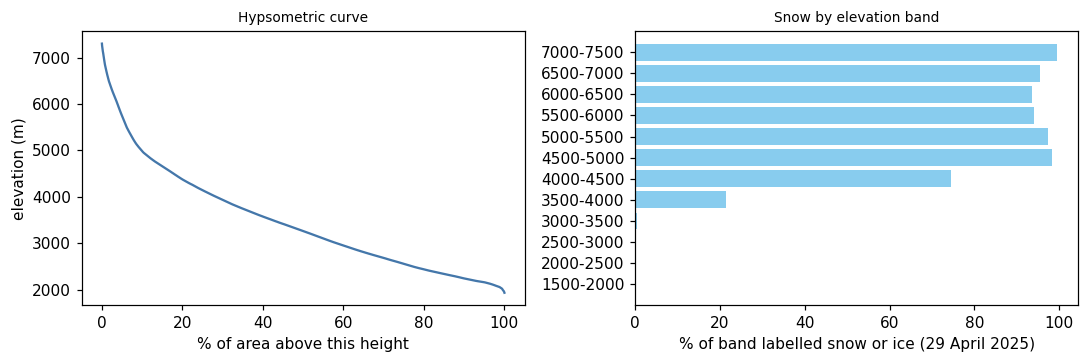

,band,share_of_area_%,median_slope_deg,snow_or_ice_%
0,1500-2000,0.5,18.4,0.0
1,2000-2500,22.4,23.3,0.0
2,2500-3000,18.8,35.7,0.1
3,3000-3500,16.0,39.3,0.5
4,3500-4000,14.0,40.8,21.3
5,4000-4500,10.6,40.2,74.5
6,4500-5000,8.0,41.9,98.3
7,5000-5500,3.7,48.7,97.5
8,5500-6000,2.3,52.7,94.1
9,6000-6500,2.2,51.4,93.7


In [7]:
bands_m = np.arange(1500, 8000, 500)
idx = np.digitize(dem, bands_m) - 1
idx_u = np.digitize(dem_utm, bands_m) - 1            # the same bands on the image grid, for the snow share
tab = pd.DataFrame({"band": [f"{bands_m[k]}-{bands_m[k] + 500}" for k in range(len(bands_m) - 1)],
                    "share_of_area_%": [100 * np.mean(idx == k) for k in range(len(bands_m) - 1)],
                    "median_slope_deg": [np.median(slope[idx == k]) if (idx == k).any() else np.nan for k in range(len(bands_m) - 1)],
                    "snow_or_ice_%": [100 * np.mean(scl[idx_u == k] == 11) if (idx_u == k).any() else np.nan for k in range(len(bands_m) - 1)]})
tab = tab[tab["share_of_area_%"] > 0.1].round(1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
h = np.sort(dem.ravel())[::-1]
ax[0].plot(100 * np.arange(1, h.size + 1) / h.size, h, color="#4477aa")
ax[0].set_xlabel("% of area above this height")
ax[0].set_ylabel("elevation (m)")
ax[0].set_title("Hypsometric curve", fontsize=9)
ax[1].barh(tab.band, tab["snow_or_ice_%"], color="#88ccee")
ax[1].set_xlabel("% of band labelled snow or ice (29 April 2025)")
ax[1].set_title("Snow by elevation band", fontsize=9)
plt.tight_layout()
plt.show()
tab

# A profile across the valley

A **profile** samples the DEM along a line. Across the Hunza valley it shows the shape carved by ice and water. Rivers
cut **V-shaped** valleys by eroding their beds; glaciers, which fill the valley, widen and deepen it into a
**U-shape** with steep walls and a flatter floor. The Karakoram is one of the fastest-rising mountain ranges on Earth,
pushed up by the collision of the Indian and Eurasian plates (about 4 cm per year of convergence across the
Himalaya-Karakoram system), and its rivers and glaciers cut down about as fast as it rises, which is why relief here is
among the greatest anywhere.

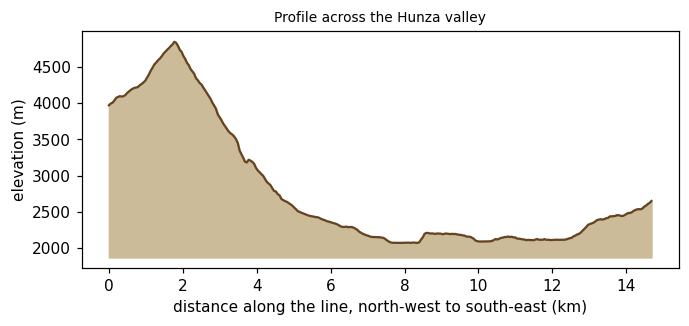

from 4,846 m to 2,073 m and back over 14.7 km


In [8]:
lon = np.linspace(74.60, 74.72, 300)
lat = np.linspace(36.36, 36.27, 300)
cols = ((lon - dtf.c) / dtf.a).astype(int)
rows_ = ((lat - dtf.f) / dtf.e).astype(int)
prof = dem[rows_, cols]
dist = np.concatenate([[0], np.cumsum(np.hypot(np.diff(lon) * 111320 * np.cos(lat0), np.diff(lat) * 110950))]) / 1000
plt.figure(figsize=(7, 2.8))
plt.fill_between(dist, prof, prof.min() - 200, color="#ccbb99")
plt.plot(dist, prof, color="#664422")
plt.xlabel("distance along the line, north-west to south-east (km)")
plt.ylabel("elevation (m)")
plt.title("Profile across the Hunza valley", fontsize=9)
plt.show()
print(f"from {prof.max():,.0f} m to {prof.min():,.0f} m and back over {dist[-1]:.1f} km")

# What to remember

* A DEM's heights have a datum; know whether it is a surface or a terrain model, and its errors on steep ground.
* Convert pixel sizes to metres before computing slope; test the formula on a surface with a known answer.
* Illumination, $\cos i$, explains much of the brightness in mountain images; correct it before comparing slopes.
* Report mountain results by elevation band, and remember the lapse rate behind them.

**Exercises.** (1) Compute slope with numpy's `gradient` and compare it with Horn's method. (2) Repeat the
C-correction for the near-infrared band, using vegetation pixels. (3) Draw a profile along the river instead of
across it and estimate its gradient in metres per kilometre.